## Processing and categorizing the Town and District Names

#### 14.04.2026

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
cd ../output

/home/ina/Desktop/thesis/Thesis-Project/article-scraping/output


In [67]:
data = pd.read_csv('02_austria_flood_impact_summary.csv')

#### Checking out the Articles after the LLM categorization

In [68]:
articles_df = pd.read_csv("/home/ina/Desktop/thesis/Thesis-Project/article-scraping/output/00_articles_df.csv")
filtered_df = articles_df[["Gassen" in i for i in articles_df["body"]]]
filtered_df.head()

,title,body,date,source,url
236,"""Es ist ein Drama"" – bittere Momente beim Aufr...",Für strahlende Feuerwehr-Gesichter sorgt aktue...,2024-09-22 20:19:00,HEUTE,https://www.heute.at/s/es-ist-ein-drama-bitter...
238,Evakuierungen mit Heli – Melkfluss flutete Gem...,"Dramatische Lage in NÖ, wie auch das Beispiel ...",2024-09-16 12:53:00,HEUTE,https://www.heute.at/s/evakuierungen-mit-heli-...


In [5]:
filtered_df.iloc[1].body

'Dramatische Lage in NÖ, wie auch das Beispiel in Zelking-Matzleinsdorf zeigt. Die Feuerwehren der Gemeinde Zelking-Matzleinsdorf stehen seit Freitag, 13.09.2024, im Einsatz für die Vorbereitungen auf ein Hochwasser. Am Sonntag, 15.09.2024, fand am Nachmittag der Melkfluss in der Gemeinde den Pegel-Höchststand und trat großflächig über die Ufer. Viele Häuser und Straßen stehen unter Wasser. Seit Freitag bereitete sich die FF Matzleinsdorf auf einen Hochwassereinsatz vor. Am Freitag und Samstag wurden Sandsäcke gefüllt, diese konnten von der Bevölkerung abgeholt werden und weitere Vorbereitungen wurden getroffen. Am Sonntag um 02:25 Uhr wurde die FF Matzleinsdorf dann alarmiert zum Evakuieren des FF-Hauses in Spielberg-Pielach aufgrund eines Hochwassers. Dort konnte mit der Mannschaft beim Räumen des FF-Hauses und des angrenzenden Vereinshauses eines Fußballvereins geholfen werden. Kurz danach um 05:30 Uhr am Sonntag wurde die Mannschaft der FF Matzleinsdorf nochmals mit Sirenenalarm al

In [69]:
# drop if missing in "Town"

data.dropna(inplace= True)

In [70]:
# manually change some district and town names (from llm versuch #2)
data["District"] = np.where(data["District"] == "Sankt Pölten-Land", "St. Pölten-Land", data["District"])
data["District"] = np.where(data["Town"] == "Krems", "Krems (Stadt)", data["District"])
data["District"] = np.where(data["Town"] == "Krems an der Donau", "Krems (Stadt)", data["District"])
data["District"] = np.where(data["District"] == "Krems", "Krems-Land", data["District"])
data["District"] = np.where(data["District"] == "Linz", "Linz (Stadt)", data["District"])
data["District"] = np.where(data["District"] == "Steyr", "Steyr (Stadt)", data["District"])
data["Town"] = np.where(data["Town"] == "Pottenbrunn", "St. Pölten", data["Town"])
data["Town"] = np.where(data["Town"] == "St. Pölten (Stadt)", "St. Pölten", data["Town"])
data["District"] = np.where(data["Town"] == "St. Pölten", "St. Pölten (Stadt)", data["District"])
data["District"] = np.where(data["District"] == "Vienna", "Wien", data["District"])
data["Town"] = np.where(data["Town"] == "Alberndorf", "Alberndorf in der Riedmark", data["Town"])
data["District"] = np.where(data["District"] == "Braunau am Inn", "Braunau", data["District"])
data["District"] = np.where((data["District"] == "Eisenstadt-Umgebung") & (data["Town"] == "Neudörfl"), "Mattersburg", data["District"])
data["District"] = np.where(data["District"] == "Flachgau", "Salzburg-Umgebung", data["District"])



# To remove:
# District = Völkermarkt (kommt in keinem Artikel nicht vor und keine Info bei Google-Suche)
# District = ["Lower Austria (Niederösterreich)", "Niederösterreich", "Waldviertel"] --> no specific towns; wrong categorization

data = data[~data["District"].isin(["Waldviertel", "Lower Austria (Niederösterreich)", "Niederösterreich", "Völkermarkt", "Klagenfurt am Wörthersee", "Villach-Land"])]
data = data[~data["Town"].isin(["Gassen", "Markersdorf", "Mittelkilling", "Pielachtal", "Raum St. Pölten", "Rosbruck", "St. Bernhard-Frauenhofen", "Vomp-Hinterriß",
                                "Wastl am Wald", "Weinzierl am Walde", "Wohlfahrts"])] # Gassen is part of Zelkin; Markersdorf could be two towns and I don't know which one it is

In [71]:
# # manually change some district and town names (from llm versuch #1)

# data["District"] = np.where(data["District"] == "Krems (Statutarstadt)", "Krems (Stadt)", data["District"])
# data["District"] = np.where(data["District"] == "Krems an der Donau", "Krems (Stadt)", data["District"])
# data["District"] = np.where(data["District"] == "Krems", "Krems (Stadt)", data["District"])
# data["District"] = np.where(data["District"] == "St. Pölten Land", "St. Pölten-Land", data["District"])
# data["District"] = np.where(data["District"] == "Sankt Pölten-Land", "St. Pölten-Land", data["District"])
# data["District"] = np.where(data["District"] == "Salzburg-Stadt", "Salzburg (Stadt)", data["District"])
# data["District"] = np.where(data["District"] == "Vienna", "Wien", data["District"])

# data["Town"] = np.where(data["Town"] == "13. Bezirk", "Hietzing", data["Town"])
# data["Town"] = np.where(data["Town"] == "14. Bezirk", "Penzing", data["Town"])
# data["Town"] = np.where(data["Town"] == "10. Bezirk", "Favoriten", data["Town"])
# data["Town"] = np.where(data["Town"] == "11. Bezirk", "Simmering", data["Town"])
# data["Town"] = np.where(data["Town"] == "12. Bezirk", "Meidling", data["Town"])
# data["Town"] = np.where(data["Town"] == "20. Bezirk", "Brigittenau", data["Town"])
# data["Town"] = np.where(data["Town"] == "23. Bezirk", "Liesing", data["Town"])
# data["Town"] = np.where(data["Town"] == "14. Wiener Gemeindebezirk", "Penzing", data["Town"])# recode vienna districts

data["Town"] = np.where(data["Town"].str.contains("Hietzing"), "Hietzing", data["Town"])
data["Town"] = np.where(data["Town"].str.contains("Penzing"), "Penzing", data["Town"])
data["Town"] = np.where(data["Town"].str.contains("Innere Stadt"), "Innere Stadt", data["Town"])
data["Town"] = np.where(data["Town"] == "14. Bezirk", "Penzing", data["Town"])
data["Town"] = np.where(data["Town"].str.contains("Liesing"), "Liesing", data["Town"])
data["Town"] = np.where(data["Town"].str.contains("Landstraße"), "Landstraße", data["Town"])
data["Town"] = np.where(data["Town"].str.contains("Leopoldstadt"), "Leopoldstadt", data["Town"])
data["Town"] = np.where(data["Town"].str.contains("Brigittenau"), "Brigittenau", data["Town"])
data = data[~data["Town"].isin(["Wien", "Vienna", "Vienna (Entire City)"])]
data["Town"] = np.where(data["Town"] == "Bahnhof Tullnerfeld", "Langenrohr", data["Town"])
data["Town"] = np.where(data["Town"] == "Drummling", "Drumling", data["Town"])
data["Town"] = np.where(data["Town"] == "Freiland", "Lilienfeld", data["Town"])
data["Town"] = np.where(data["Town"] == "Gars", "Gars am Kamp", data["Town"])
data["District"] = np.where((data["Town"] == "Grafenwörth") & (data["District"] == "Tulln"), "Krems-Land", data["District"])
data["Town"] = np.where(data["Town"].str.contains("Hadersdorf"), "Hadersdorf", data["Town"])
data["Town"] = np.where(data["Town"] == "Krems", "Krems an der Donau", data["Town"])
data["Town"] = np.where(data["Town"] == "Krumau", "Krumau am Kamp", data["Town"])
data["Town"] = np.where(data["Town"].str.contains("Markersdorf"), "Markersdorf an der Pielach", data["Town"])
data["Town"] = np.where(data["Town"] == "Oberkilling", "Weißenkirchen an der Perschling", data["Town"]) # closest town
data["Town"] = np.where(data["Town"].str.contains("Ottenstein"), "Peygarten", data["Town"]) # closest town
data["Town"] = np.where(data["Town"].str.contains("Rabenstein"), "Rabenstein an der Pielach", data["Town"])
data["Town"] = np.where(data["Town"] == "Pramerdorf", "St. Florian am Inn", data["Town"]) # closest town
data["Town"] = np.where(data["Town"].str.contains("Pressbaum"), "Pressbaum", data["Town"])
data["Town"] = np.where(data["Town"] == "Rust", "Rust im Tullnerfeld", data["Town"])
data["Town"] = np.where(data["Town"] == "Rotheau", "Göblasbruck", data["Town"]) # closest town
data["Town"] = np.where(data["Town"] == "Rottenegg", "St. Gotthard im Mühlkreis", data["Town"]) # closest town
data["Town"] = np.where(data["Town"] == "Seekirchen", "Seekirchen am Wallersee", data["Town"]) # closest town
data["Town"] = np.where(data["Town"] == "Steyr (Stadt)", "Steyr", data["Town"])
data["Town"] = np.where(data["Town"] == "Tulln", "Tulln an der Donau", data["Town"])
data["Town"] = np.where(data["Town"] == "Wels (Stadt)", "Wels", data["Town"])
data["Town"] = np.where(data["Town"] == "Zwentendorf", "Zwentendorf an der Donau", data["Town"])
data["Town"] = np.where(data["Town"] == "Unterlaussa", "Altenmarkt bei Sankt Gallen", data["Town"]) # closest town
data["Town"] = np.where(data["Town"] == "Vestenpoppen", "Waidhofen an der Thaya", data["Town"]) # closest town



In [72]:
# collapse duplicates created

data = data.groupby(["Town", "District"], as_index=False)["Flood_Mention_Count"].sum()

#check = data.groupby(["Town", "District"])["Flood_Mention_Count"].sum()

### Focussing on Districts

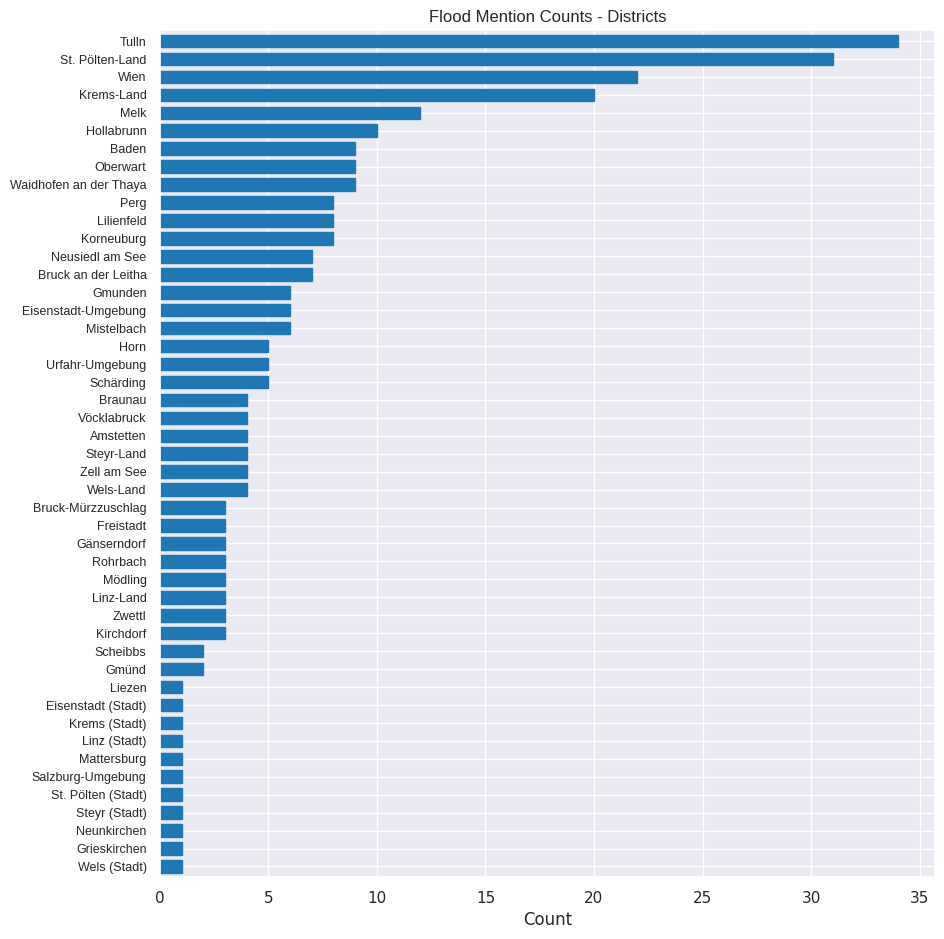

In [8]:
# Plot Districts

plt.figure(figsize=(10, 11)) 
sns.set_theme(style="darkgrid")
# Calculate value counts
counts = data['District'].value_counts()

# Plot value counts
counts.plot(kind='barh', color='#1F78B4', edgecolor = '#1F78B4',width=0.7)
plt.xlabel('Count')
plt.ylabel("")
plt.title('Flood Mention Counts - Districts', fontname = "Liberation Sans")
plt.yticks(fontname = "Liberation Sans", fontsize = 9)
plt.gca().invert_yaxis()
plt.show()

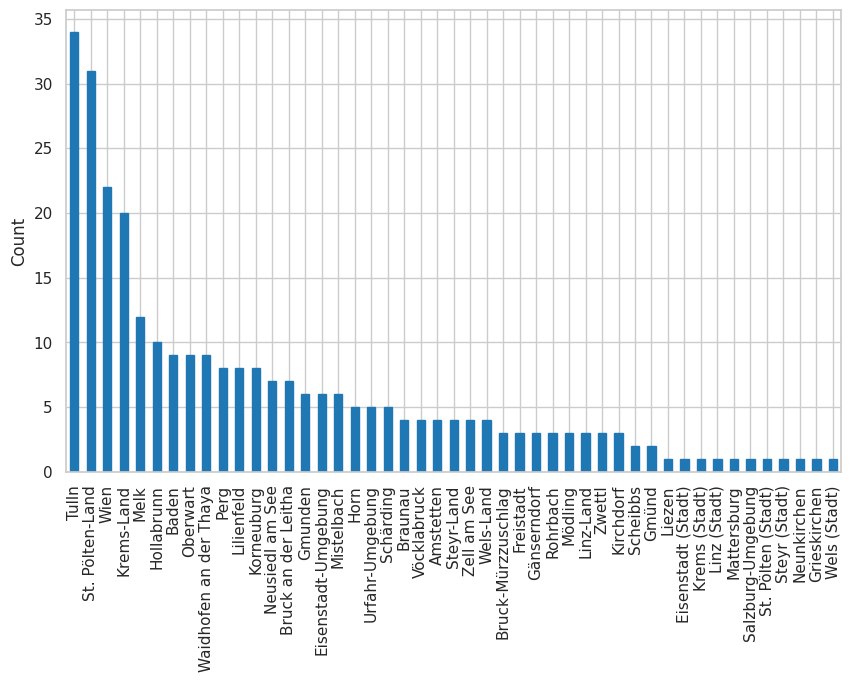

In [9]:

# 1. Set a theme (sns.set_theme adds a clean grid and nice default fonts)
#sns.set_theme(style="darkgrid")
sns.set_theme(style="whitegrid", palette="pastel")
#plt.style.use('classic')

plt.figure(figsize=(10, 6)) 

# Calculate value counts
counts = data['District'].value_counts()

# 2. Plot value counts
# I'm using ax to make referencing the plot easier for bar labels
ax = counts.plot(kind='bar', color='#1F78B4', edgecolor='#1F78B4')

# 3. Tilt the x-ticks to 45 degrees

plt.xlabel('')
plt.ylabel('Count')
#plt.title('Flood Mention Counts - Districts', fontsize=14)

#plt.tight_layout() # Ensures labels don't get cut off after rotation
plt.show()

In [73]:
sorted(counts.Flood_Mention_Count, reverse = True)

[37, 18, 13, 9, 9, 9, 7, 6, 6, 5, 4, 4, 4, 4, 4, 4, 3, 3, 2, 2, 1, 1]

In [74]:
counts = data[data["District"] == "Wien"].Flood_Mention_Count

xticks = []
for i in data.iloc[counts.index]["Town"]:
    xticks.append(i)
    
counts = pd.DataFrame(counts)
counts["dist"] = xticks
counts = counts.set_index("dist")

counts.sort_values(by ="Flood_Mention_Count", ascending = False, inplace = True)

<Figure size 1000x800 with 0 Axes>

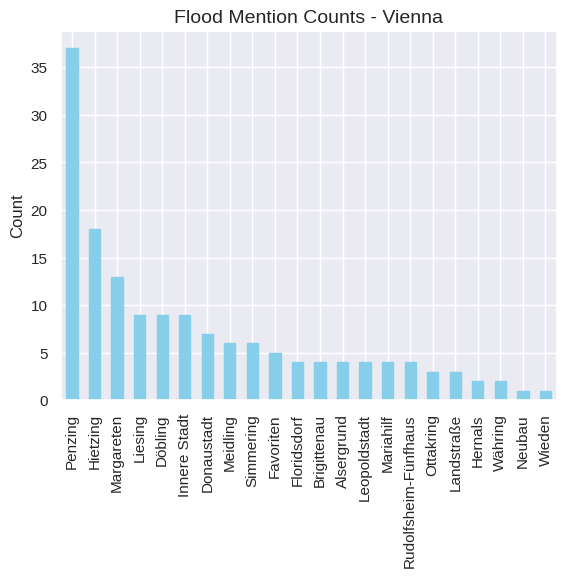

In [46]:
# Plot Vienna

plt.figure(figsize=(10, 8))
sns.set_theme(style="darkgrid")


# Plot value counts
counts.plot(kind='bar', color='skyblue', edgecolor = "skyblue")

plt.xlabel('')
plt.ylabel('Count', fontname = "Liberation Sans")
#plt.xticks(data.iloc[counts.index]["Town"])
plt.title('Flood Mention Counts - Vienna', fontsize=14, fontname = "Liberation Sans")
plt.xticks(fontname = "Liberation Sans")
plt.yticks(fontname = "Liberation Sans")
plt.legend().remove()
plt.show()

In [ ]:
# collapse duplicates created

In [ ]:
# # create a dictionary with all districts and Gemeindekennzahlen

# # from the list, the following districts would be selected:

# print(regions_total)

# # this corresponds to the following "Gemeindekennzahlen":

# regions = {"St. Pölten-Land": "319",
#            "Tulln": "321",
#            "Krems (Stadt)": "301",
#            "Melk": "315",
#            "Krems-Land": "313",
#            "St. Pölten": "302",
#            "Waidhofen an der Thaya": "322",
#            "Hollabrunn": "310",
#            "Mistelbach": "316",
#            "Lilienfeld": "314",
#            "Baden": "306",
#            "Steyr-Land": "415",
#            "Oberwart": "109",
#            "Neusiedl am See": "107",
#            "Bruck an der Leitha": "307",
#            "Kufstein": "106", ##???
#            "Horn": "311",
#            "Perg": "411",
#            "Amstetten": "305",
#            "Korneuburg": "312",
#            "Eisenstadt-Umgebung": "103",
#            "Urfahr-Umgebung": "416",
#            "Gmunden":"407",
#            "Mödling": "316",
#            "Vöcklabruck": "417",
#            "Scheibbs": "320",
#            "Schärding": "414",
#            "Linz-Land": "410",
#            "Braunau": "404",
#            "Gänserndorf": "308",
#            "Schwaz": "709", ##??
#            "Zell am See": "506", ##??
#            "Freistadt": "406",
#            "Wels-Land": "418",
#            "Gmünd": "309",
#            "Rohrbach": "413",
#            "Hartberg-Fürstenfeld":"622",
#      #       "Bruck-Mürzzuschlag": "621", # hashed out: these districts were mentioned 3 but not 4 times
#      #       "Zwettl": "325",
#      #  #     "Villach-Land":"",
#      #       "Kirchdorf": "409",
#      #       "Neunkirchen": "318",
#            "Penzing": "914"}

# # Wiener Neustadt?? Fehlt in der Liste!
# # Warum ist Kufstein auf der Liste??

['St. Pölten-Land', 'Tulln', 'Krems (Stadt)', 'Melk', 'Krems-Land', 'St. Pölten', 'Waidhofen an der Thaya', 'Hollabrunn', 'Mistelbach', 'Lilienfeld', 'Baden', 'Steyr-Land', 'Oberwart', 'Neusiedl am See', 'Bruck an der Leitha', 'Kufstein', 'Horn', 'Perg', 'Amstetten', 'Korneuburg', 'Eisenstadt-Umgebung', 'Urfahr-Umgebung', 'Gmunden', 'Mödling', 'Vöcklabruck', 'Scheibbs', 'Schärding', 'Linz-Land', 'Braunau', 'Gänserndorf', 'Schwaz', 'Zell am See', 'Freistadt', 'Wels-Land', 'Braunau am Inn', 'Gmünd', 'Rohrbach', 'Hartberg-Fürstenfeld', 'Penzing']


In [ ]:
# save to txt file


# with open("../output/final_district_list.txt", "w") as f:
#     for l in regions:
#         f.write(l + "\n")


# final_district_list = open("../output/final_district_list.txt", 'wt')
# final_district_list.write(str(regions))
# final_district_list.close()

### Focussing on Towns

In [75]:
municipalities = {
    "Absdorf": "32101",
    "Ach": "40414",
    "Achleiten": "41009",
    "Aflenz": "61045",
    "Aigen-Schlägl": "41343",
    "Alberndorf in der Riedmark": "41601",
    "Alland": "30601",
    "Alsergrund": "90901",
    "Altenberg bei Linz": "41602",
    "Altenburg": "31101",
    "Altenmarkt an der Triesting": "30602",
    "Altenwörth": "32114",
    "Altmünster": "40701",
    "Amstetten": "30502",
    "Angern an der March": "30803",
    "Asparn": "32119",
    "Attersee": "41702",
    "Atzenbrugg": "32104",
    "Bad Aussee": "61207",
    "Bad Ischl": "40703",
    "Langenrohr": "32119",
    "Baumgartenberg": "41103",
    "Blumau-Neurißhof": "30646",
    "Brigittenau": "92001",
    "Bruckneudorf": "10703",
    "Böheimkirchen": "31903",
    "Bösendürnbach": "31021",
    "Deutsch Jahrndorf": "10704",
    "Dietersdorf": "32131",
    "Dimbach": "41104",
    "Donaustadt": "92201",
    "Dornach": "61051",
    "Drumling": "10923",
    "Döbling": "91901",
    "Dürnrohr": "20115",
    "Dürnstein": "31304",
    "Ebendorf": "31633",
    "Ebensee": "40704",
    "Ebreichsdorf": "30607",
    "Edt bei Lambach": "41806",
    "Eibelsau": "31911",
    "Einsiedl": "32131",
    "Eisenstadt": "10101",
    "Engelhartszell": "41407",
    "Enns": "41005",
    "Erpersdorf": "32141",
    "Eschenau": "31402",
    "Favoriten":"91001",
    "Fischamend": "30730",
    "Floridsdorf": "92101",
    "Frankenfels": "31906",
    "Frauendorf": "31043",
    "Freinberg": "41410",
    "Gablitz": "31949",
    "Gars am Kamp": "31106",
    "Gattendorf": "10706",
    "Gedersdorf": "31310",
    "Gmunden": "40705",
    "Gmünd": "30908",
    "Goldwörth": "41608",
    "Grafenegg": "31308",
    "Grafenwörth": "32107",
    "Greifenstein": "32142",
    "Grein": "41105",
    "Groß Sierning": "31911",
    "Grub": "31726",
    "Grünau im Almtal": "40707",
    "Grünburg": "40902",
    "Göllersdorf": "31008",
    "Hadersdorf": "31315",
    "Hadersfeld": "32142",
    "Hainburg": "30710",
    "Hallstatt": "40709",
    "Haringsee": "30825",
    "Harmannsdorf": "31207",
    "Haunoldstein": "31911",
    "Heinrichsreith": "31104",
    "Helpfau-Uttendorf": "40413",
    "Hernals": "91701",
    "Herzogenburg": "31912",
    "Hietzing": "91301",
    "Himberg": "30732",
    "Hofkirchen im Traunkreis": "41008",
    "Hofstetten": "31909",
    "Hohenau an der March": "30827",
    "Hollabrunn": "31022",
    "Hollenbach": "32220",
    "Horn": "31109",
    "Hornstein": "10304",
    "Höbersdorf": "31226",
    "Höflein": "32144",
    "Innere Stadt": "90101",
    "Judenau": "32112",
    "Kammern": "31315",
    "Kapelln": "31915",
    "Katzelsdorf am Wienerwald": "32313",
    "Kierling": "32144",
    "Kirchberg an der Pielach": "31918",
    "Kirchdorf an der Krems": "40905",
    "Kirnberg an der Mank": "31515",
    "Klausen-Leopoldsdorf": "30616",
    "Klein Pöchlarn": "31516",
    "Kleinreifling": "41522",
    "Kleinschönbichl": "32141",
    "Klosterneuburg": "32144",
    "Korneuburg": "31213",
    "Krems an der Donau": "30101",
    "Krenglbach": "41810",
    "Kritzendorf": "32144",
    "Krumau am Kamp": "31321",
    "Königstetten": "32116",
    "Königswiesen": "40608",
    "Laa an der Thaya": "31629",
    "Lackenhof": "32001",
    "Ladendorf": "31630",
    "Landstraße": "90301",
    "Langenlebarn": "32135",
    "Langenlois": "31322",
    "Langenzersdorf": "31214",
    "Langmannersdorf": "31946",
    "Lanzendorf": "31633",
    "Laxenburg": "31715",
    "Lehenrotte": "31414",
    "Leiben": "31519",
    "Leithaprodersdorf": "10306",
    "Leopoldstadt": "90201",
    "Liesing": "92301",
    "Lilienfeld": "31407",
    "Limberg": "31026",
    "Linz": "40101",
    "Lochen am See": "40419",
    "Lofer": "50610",
    "Loich": "31920",
    "Loosdorf": "31520",
    "Maissau": "31026",
    "Marbach": "31522",
    "Margareten": "90501",
    "Mariahilf": "90601",
    "Mariazell": "62142",
    "Markersdorf an der Pielach": "31922",
    "Markl": "32223",
    "Markt Allhau": "10912",
    "Marktl": "31407",
    "Matzleinsdorf": "31550",
    "Matzlesschlag": "32223",
    "Mauerbach": "31950",
    "Mauerkirchen": "40422",
    "Mautern an der Donau": "31327",
    "Mauthausen": "41111",
    "Meidling": "91201",
    "Melk": "31524",
    "Michelhausen": "32120",
    "Mischendorf": "10914",
    "Mistelbach": "31633",
    "Mondsee": "41712",
    "Moosbierbaum": "32104",
    "Mödling": "31717",
    "Mörbisch": "10307",
    "Neubau": "90701",
    "Neudörfl": "10607",
    "Neufeld": "10309",
    "Neulengbach": "31926",
    "Neusiedl": "32119",
    "Neustift": "41329",
    "Nickelsdorf": "10714",
    "Niederschleinz": "31043",
    "Nußbach": "40910",
    "Ober-Grafendorf": "31929",
    "Weißenkirchen an der Perschling": "31946",
    "Oberwart": "10917",
    "Offenhausen": "41814",
    "Ottakring": "91601",
    "Peygarten": "31336",
    "Paasdorf": "31633",
    "Pama": "10715",
    "Penzing": "91401",
    "Perg": "41116",
    "Perschling": "31946",
    "Petronell-Carnuntum": "30718",
    "Pichl bei Wels": "41816",
    "Pinkafeld": "10918",
    "Pischelsdorf": "32141",
    "Pixendorf": "32120",
    "Pottenstein": "30627",
    "Potzneusiedl": "10726",
    "St. Florian am Inn": "41418",
    "Pregarten": "40614",
    "Pressbaum": "31951",
    "Prinzersdorf": "31932",
    "Purkersdorf": "31952",
    "Pölla": "32520",
    "Raabs an der Thaya": "32216",
    "Rabenstein an der Pielach": "31935",
    "Rainfeld": "31412",
    "Rammersdorf": "31938",
    "Rastenfeld": "31336",
    "Retz": "31037",
    "Rosenburg-Mold": "31121",
    "Rossatz-Arnsdorf": "31338",
    "Rotenturm an der Pinka": "10921",
    "Göblasbruck": "31947",
    "St. Gotthard im Mühlkreis": "41621",
    "Rudolfsheim-Fünfhaus": "91501",
    "Ruprechtshofen": "31537",
    "Rust im Tullnerfeld": "32120",
    "Saxen": "41123",
    "Scharndorf": "30722",
    "Scheibbs": "32013",
    "Schreibersdorf": "10927",
    "Schwarzenbach": "31939",
    "Schwechat": "30740",
    "Schärding": "41422",
    "Schönberg": "31355", # Krems-Land    
    "Seekirchen am Wallersee": "50339", # Salzburg-Umgebung
    "Senftenberg": "31343",
    "Sieghartskirchen": "32131",
    "Sierndorf": "31226",
    "Simmering": "91101",
    "Sitzendorf": "31043",
    "Sonnberg": "41623", #urfahr
    "Spielberg": "31524",
    "Spitz": "31344",
    "St. Andrä-Wördern": "32142",
    "St. Christophen": "31926", 
    "St. Florian": "41013", # linz land
    "St. Georgen am Ybbsfelde": "30527",
    "St. Leonhard am Forst": "31539",
    "St. Leonhard bei Freistadt": "40617",
    "St. Lorenz": "41735", #vöcklabruck
    "St. Martin": "30932", # gmünd 
    "St. Martin bei Lofer": "50620", #zell
    "St. Nikola an der Donau": "41121",
    "St. Oswald": "41333",
    "St. Pölten": "30201",
    "St. Valentin": "30531",
    "St. Veit": "31412",
    "Steyr": "40201",
    "Stiefern": "31355",
    "Stockerau": "31230",
    "Stotzing": "10321",
    "Straß im Straßertale": "31346",
    "Tattendorf": "30636",
    "Teesdorf": "30637",
    "Ternitz": "31839",
    "Thalheim": "41823",
    "Thörl": "62147",
    "Traiskirchen": "30639",
    "Traismauer": "31943",
    "Trasdorf": "32104",
    "Tresdorf": "31216",
    "Tulln an der Donau": "32135",
    "Tullnerbach": "31953",
    "Tullnerfeld": "32112",
    "Türnitz": "31414",
    "Unken": "50623",
    "Untergrafendorf": "31903",
    "Altenmarkt bei Sankt Gallen": "61205",
    "Untermallebarn": "31226",
    "Unterschützen": "10916",
    "Vestenötting": "32220",
    "Vitis": "32219",
    "Vöcklabruck": "41746",
    "Waidhofen an der Thaya": "32220",
    "Waidhofen an der Thaya-Land": "32221",    
    "Wallern an der Trattnach": "40832",
    "Wallsee-Sindelburg": "30538",
    "Wartberg an der Krems": "40922",
    "Wegscheid am Kamp": "32520",
    "Weidling": "32144",
    "Weißbach bei Lofer": "50627",
    "Weißenkirchen in der Wachau": "31351",
    "Wels": "40301",
    "Weyer": "41522",
    "Wieden": "90401",
    "Wiesfleck": "10927",
    "Wilhelmsburg": "31947",
    "Wimpassing": "10318",
    "Windigsteig": "32223",
    "Wolfsgraben": "31954",
    "Währing": "91801",
    "Würmla": "32139",
    "Ybbs": "31549",
    "Zelking-Matzleinsdorf": "31550",
    "Zellerndorf": "31052",
    "Zurndorf": "10724",
    "Zwentendorf an der Donau": "32141",
    "Zwettl": "32530",
    "Zwölfaxing": "30741",
    "Zöbing": "31322",
}

In [76]:
df_towns = pd.DataFrame.from_dict(municipalities, orient='index', dtype=None, columns=None)
#df_towns.pivot(*, columns = )

In [77]:
df_towns["Town"] = df_towns.index

In [78]:
keys = np.arange(0,289)
df_towns = df_towns.set_index(keys)
df_towns = df_towns.rename(columns={0: "town_kz", "Town": "Town"})


In [15]:
df_towns.head()

,town_kz,Town
0,32101,Absdorf
1,40414,Ach
2,41009,Achleiten
3,61045,Aflenz
4,41343,Aigen-Schlägl


In [79]:
df_towns["town_kz"].drop_duplicates # no duplicates!

<bound method Series.drop_duplicates of 0      32101
1      40414
2      41009
3      61045
4      41343
       ...  
284    10724
285    32141
286    32530
287    30741
288    31322
Name: town_kz, Length: 289, dtype: object>

In [80]:
# town sizes were downloaded from: https://statcube.at/statistik.at/ext/statcube/
# annual average population since 2002
# year: 2024
# Commune (aggregation by political district)

town_sizes = pd.read_csv("/home/ina/Desktop/thesis/Thesis-Project/article-scraping/output/03_town_sizes.csv", encoding='latin3')

In [81]:
town_sizes = town_sizes.rename(columns={"Commune (aggregation by political district)": "Town", "size": "size"})
town_sizes = town_sizes.iloc[:2114]

In [82]:
town_name = []
town_kz = []

for i in np.arange(0,2114):
    town_name.append(town_sizes["Town"].str.split("<")[i][0])
    town_kz.append(town_sizes["Town"].str.split("<")[i][1])

In [83]:
town_sizes["Town"] = town_name
town_sizes["town_kz"] = town_kz
town_sizes["Town"] = town_sizes["Town"].str.strip()
town_sizes["town_kz"] = town_sizes["town_kz"].str.removesuffix(">")

In [84]:
# make sure to convert both town_kz to strings
df_towns["town_kz"] = df_towns["town_kz"].astype(str).str.strip()
town_sizes["town_kz"] = town_sizes["town_kz"].astype(str).str.strip()

In [99]:
towns_merged = df_towns.merge(
    town_sizes[["size", "town_kz"]], 
    on="town_kz", 
    how="left"
)

In [100]:
merged_df = data.merge(
    towns_merged, 
    on="Town", 
    how="left"
)

In [24]:
merged_df.head()

,Town,District,Flood_Mention_Count,town_kz,size
0,Absdorf,Tulln,1,32101,2469
1,Ach,Braunau,1,40414,3405
2,Achleiten,Schärding,1,41009,3093
3,Aflenz,Bruck-Mürzzuschlag,1,61045,6525
4,Aigen-Schlägl,Rohrbach,1,41343,3267


In [101]:
merged_df["size"] = np.where(merged_df["Town"] == "Dürnrohr", "1000", merged_df["size"]) # the size of dürnrohr is nowehere to be found but it's tiny, sure not more than 1000

In [102]:
merged_df["Flood_Mention_Count"] = merged_df["Flood_Mention_Count"].astype(int)
merged_df["size"] = merged_df["size"].astype(int)


In [103]:
# weighted affectedness index

merged_df["flood_count_weighted"] = round(merged_df["Flood_Mention_Count"].div(merged_df["size"]) * 1000, 4)

In [104]:
merged_df["flood_count_weighted_rec"] = round(merged_df["Flood_Mention_Count"].div(merged_df["size"]**0.5) * 100, 4)

In [92]:
merged_df["flood_count_weighted_rec"]

0      2.0125
1      1.7137
2      1.7981
3      1.2380
4      1.7495
        ...  
285    4.1904
286    3.0879
287    4.8188
288    2.4405
289    2.3109
Name: flood_count_weighted_rec, Length: 290, dtype: float64

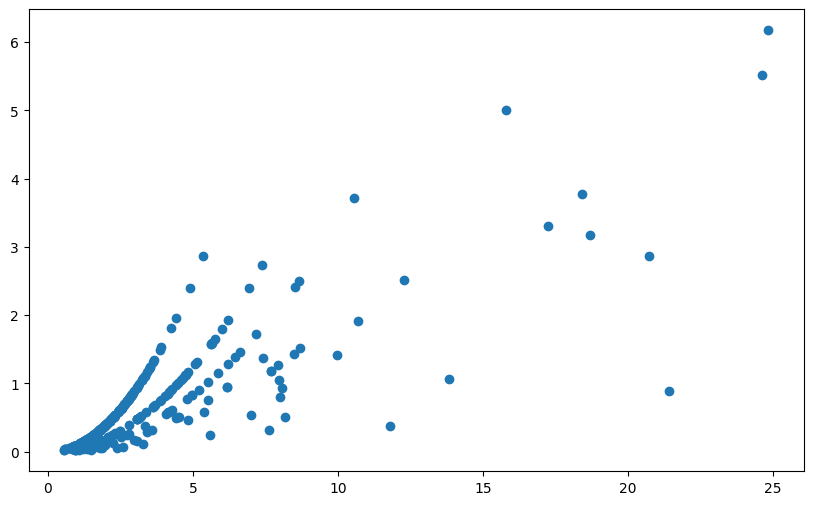

In [93]:
plt.figure(figsize = (10,6))
plt.scatter(merged_df["flood_count_weighted_rec"], merged_df["flood_count_weighted"])

''

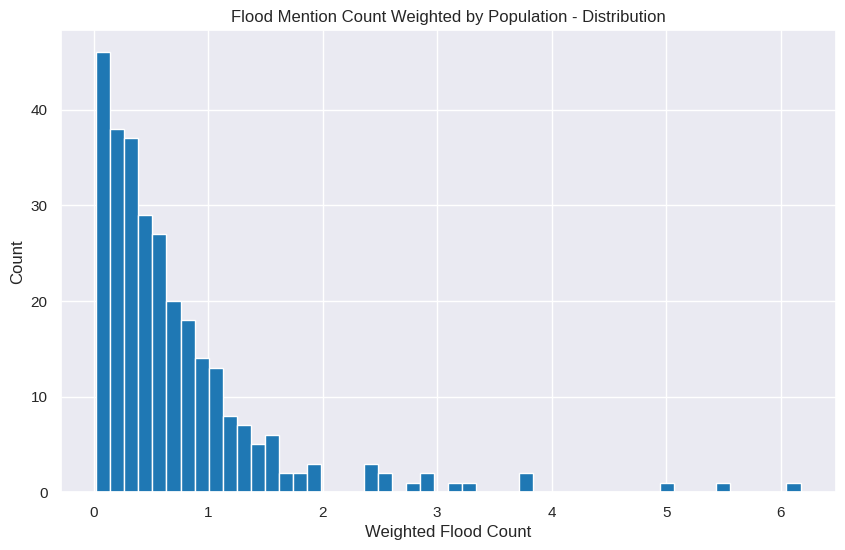

In [27]:
plt.figure(figsize = (10,6))

plt.hist(merged_df["flood_count_weighted"], bins = 50, color = "#1F78B4")
plt.title("Flood Mention Count Weighted by Population - Distribution", fontname = "Liberation Sans")
plt.xlabel("Weighted Flood Count", fontname = "Liberation Sans")
plt.xticks(fontname = "Liberation Sans")
plt.yticks(fontname = "Liberation Sans")
plt.ylabel("Count", fontname = "Liberation Sans")

;

''

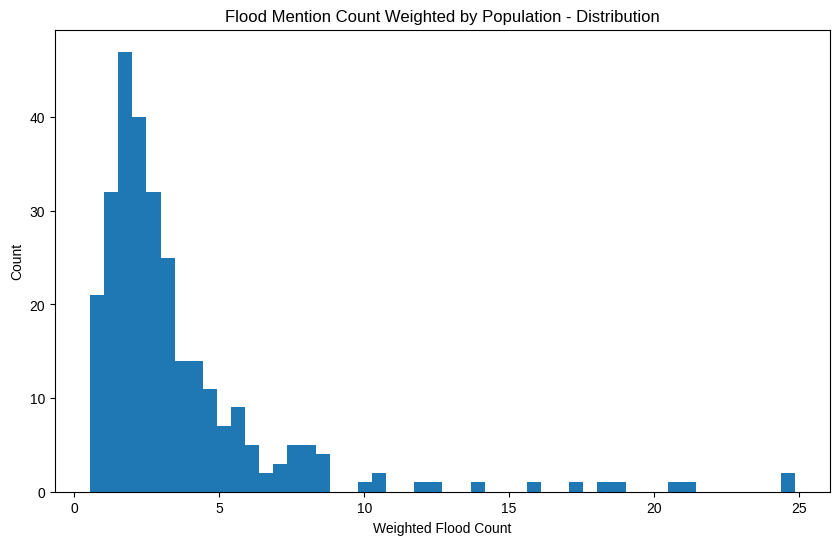

In [37]:
plt.figure(figsize = (10,6))

plt.hist(merged_df["flood_count_weighted_rec"], bins = 50, color = "#1F78B4")
plt.title("Flood Mention Count Weighted by Population - Distribution", fontname = "Liberation Sans")
plt.xlabel("Weighted Flood Count", fontname = "Liberation Sans")
plt.xticks(fontname = "Liberation Sans")
plt.yticks(fontname = "Liberation Sans")
plt.ylabel("Count", fontname = "Liberation Sans")

;

In [43]:
merged_df[merged_df["flood_count_weighted_rec"]>5]

,Town,District,Flood_Mention_Count,town_kz,size,flood_count_weighted,flood_count_weighted_rec
18,Atzenbrugg,Tulln,11,32104,3465,3.1746,18.6871
25,Böheimkirchen,St. Pölten-Land,15,31903,5243,2.8610,20.7158
34,Dürnrohr,Tulln,5,20115,1000,5.0000,15.8114
35,Dürnstein,Krems-Land,3,31304,807,3.7175,10.5605
45,Erpersdorf,Tulln,4,32141,4195,0.9535,6.1758
54,Gars am Kamp,Horn,5,31106,3475,1.4388,8.4819
55,Gattendorf,Neusiedl am See,2,10706,1515,1.3201,5.1383
56,Gedersdorf,Krems-Land,3,31310,2165,1.3857,6.4475
61,Grafenwörth,Krems-Land,5,32107,3300,1.5152,8.7039
63,Grein,Perg,4,41105,2912,1.3736,7.4125


In [46]:
merged_df[merged_df["flood_count_weighted"]<0.15].head()

,Town,District,Flood_Mention_Count,town_kz,size,flood_count_weighted,flood_count_weighted_rec
7,Alsergrund,Wien,4,90901,41631,0.0961,1.9604
13,Altmünster,Gmunden,1,40701,10076,0.0992,0.9962
14,Amstetten,Amstetten,3,30502,23899,0.1255,1.9406
23,Brigittenau,Wien,4,92001,86930,0.0460,1.3567
28,Dietersdorf,Tulln,1,32131,7867,0.1271,1.1274


In [105]:
merged_df["flood_count_weighted_rec"].mean(axis = 0)

np.float64(3.6417093103448277)

In [ ]:
#merged_df.to_csv("03_flood_count_weighted.csv")

In [106]:
cd /home/ina/Desktop/thesis/Thesis-Project/article-scraping/output

/home/ina/Desktop/thesis/Thesis-Project/article-scraping/output


In [96]:
merged_df= pd.read_csv("03_flood_count_weighted.csv")

In [97]:
merged_df.head()

,Unnamed: 0,Town,District,Flood_Mention_Count,town_kz,size,flood_count_weighted
0,281,Würmla,Tulln,10,32139,1620,6.1728
1,70,Hadersdorf,Krems-Land,11,31315,1995,5.5138
2,34,Dürnrohr,Tulln,5,20115,1000,5.0000
3,253,Tullnerfeld,Tulln,9,32112,2386,3.7720
4,35,Dürnstein,Krems-Land,3,31304,807,3.7175


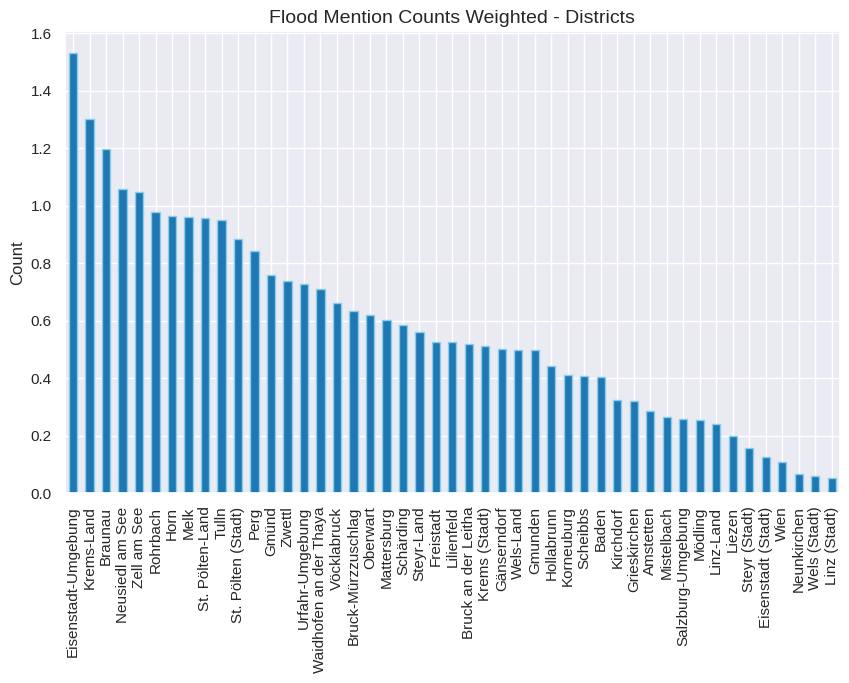

In [26]:
# Weighted Plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="darkgrid")


# Plot value counts
merged_df.groupby("District").flood_count_weighted.mean().sort_values(ascending=False).plot(kind='bar', color='#1F78B4', edgecolor = "skyblue")

plt.xlabel('')
plt.ylabel('Count', fontname = "Liberation Sans")
#plt.xticks(data.iloc[counts.index]["Town"])
plt.title('Flood Mention Counts Weighted - Districts', fontsize=14, fontname = "Liberation Sans")
plt.xticks(fontname = "Liberation Sans")
plt.yticks(fontname = "Liberation Sans")
plt.legend().remove()
plt.show()

In [58]:
merged_df[merged_df["District"] == "Wien"].Town
merged_df[merged_df["District"] == "Wien"].sort_values(by = "flood_count_weighted", ascending = False).Town

92             Innere Stadt
175                 Penzing
81                 Hietzing
138              Margareten
139               Mariahilf
33                  Döbling
7                Alsergrund
128                 Liesing
151                Meidling
216               Simmering
201    Rudolfsheim-Fünfhaus
23              Brigittenau
280                 Währing
127            Leopoldstadt
79                  Hernals
160                  Neubau
30               Donaustadt
116              Landstraße
274                  Wieden
172               Ottakring
47                Favoriten
49              Floridsdorf
Name: Town, dtype: object

ConversionError: Failed to convert value(s) to axis units: 92             Innere Stadt
175                 Penzing
81                 Hietzing
138              Margareten
139               Mariahilf
33                  Döbling
7                Alsergrund
128                 Liesing
151                Meidling
216               Simmering
201    Rudolfsheim-Fünfhaus
23              Brigittenau
280                 Währing
127            Leopoldstadt
79                  Hernals
160                  Neubau
30               Donaustadt
116              Landstraße
274                  Wieden
172               Ottakring
47                Favoriten
49              Floridsdorf
Name: Town, dtype: object

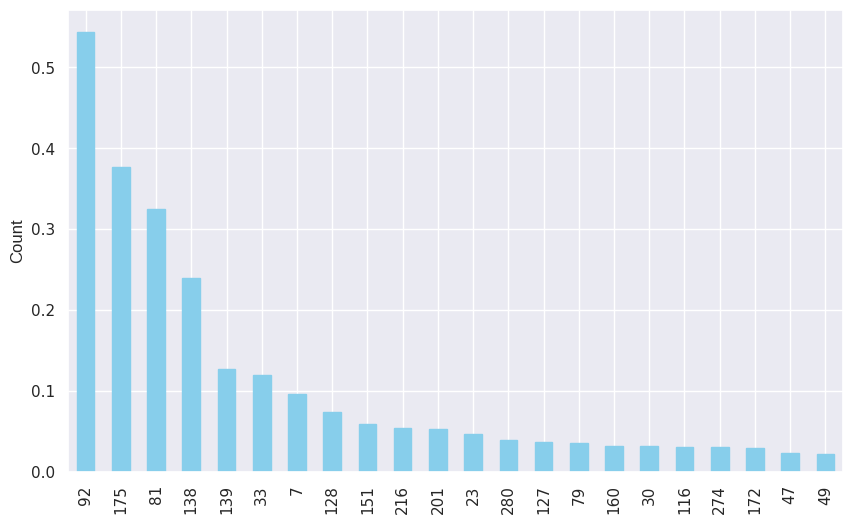

In [109]:
# Plot Vienna

plt.figure(figsize=(10, 6))
sns.set_theme(style="darkgrid")


# Plot value counts
merged_df[merged_df["District"] == "Wien"].sort_values(by = "flood_count_weighted", ascending = False).flood_count_weighted.plot(kind='bar', color='skyblue', edgecolor = "skyblue")

plt.xlabel('')
plt.ylabel('Count', fontname = "Liberation Sans")
plt.xticks(merged_df[merged_df["District"] == "Wien"].sort_values(by = "flood_count_weighted", ascending = False).Town)
plt.title('Flood Mention Counts Weighted - Districts', fontsize=14, fontname = "Liberation Sans")
plt.xticks(fontname = "Liberation Sans")
plt.yticks(fontname = "Liberation Sans")
plt.legend().remove()
plt.show()